# Feature Engineering: 100,000 Clean News Articles Dataset
**Target Variable:** `category` (Multi-class: `Technology`, `Energy`, `Health`, `Market`, `Politics`)  
**Dataset Source:** `preprocessed_articles_100k_clean.csv` (100,000 Verified Records, 0 Errors, 0 Nulls, 0 Duplicate URLs)  
**Curriculum Scope:**
1. **Target Encoding (Label Encoding)** for Multi-Class Classification
2. **Statistical & Linguistic Text Feature Extraction** (Lengths, Word Counts, Lexical Diversity, Acronyms)
3. **Temporal Feature Extraction** (Published Hour, Day of Week, Weekend Flag, Month)
4. **Categorical Feature Encoding** (One-Hot Encoding vs Frequency Encoding for Publisher Domains)
5. **Feature Scaling & Normalization** (StandardScaler vs MinMaxScaler Theory & Implementation)
6. **Text Vectorization Comparison** (Bag of Words, N-grams, TF-IDF Limitations)
7. **Transformer Embeddings Primer** (Architecture, Contextual Semantics, Dense Vectors Preview)
8. **Train/Test Stratified Split & Feature Matrix Assembly**

---


## 1. Environment Setup & Data Loading
Importing data processing, visualization, and Scikit-Learn feature engineering modules, and loading the 100,000 clean records.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

# Load Clean 100,000 Dataset
DATA_PATH = Path('preprocessed_articles_100k_clean.csv')
df = pd.read_csv(DATA_PATH)

print(f'Dataset Loaded: {len(df):,} rows  {df.shape[1]} columns')
print(f'Columns: {list(df.columns)}')
print(f'Missing Values: {df.isnull().sum().sum()}')


Dataset Loaded: 100,000 rows  11 columns
Columns: ['article_id', 'source', 'title', 'description', 'author', 'url', 'published_at', 'timezone', 'scraped_at', 'domain', 'category']
Missing Values: 0


## 2. Target Variable Encoding (Label Encoding)
### Concept:
Machine Learning algorithms and loss functions (e.g. Cross-Entropy Loss) require target classes to be numeric integers rather than raw string categories.
- We use **`LabelEncoder`** from `sklearn.preprocessing` to map the 5 discrete target categories into integers: `[0, 1, 2, 3, 4]`.
- This is distinguished from One-Hot Encoding, which is reserved for independent input features to avoid imposing an artificial order.


=== TARGET CATEGORY ENCODING MAPPING ===
Category Name  Encoded ID  Article Count Percentage (%)
       Energy           0          18188         18.19%
       Health           1          16534         16.53%
       Market           2          12797         12.80%
     Politics           3          10003         10.00%
   Technology           4          42478         42.48%


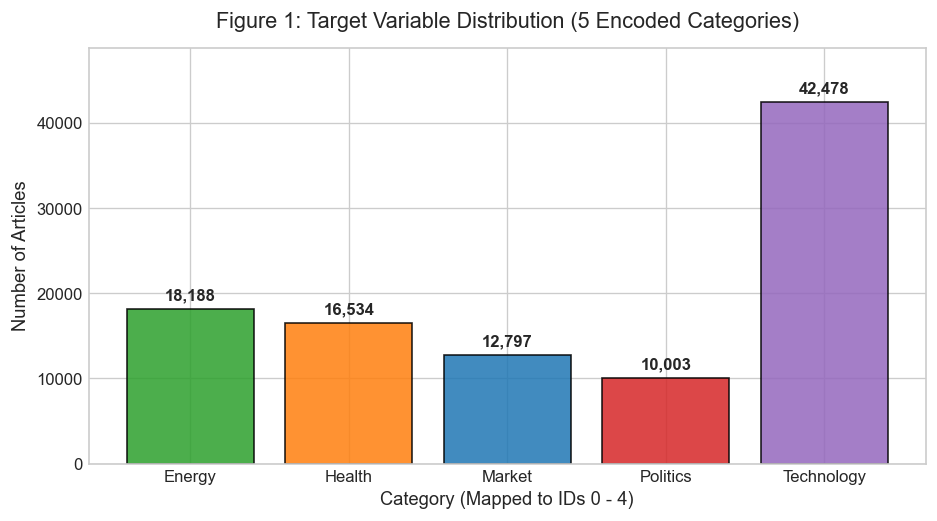

In [1]:
# 1. Initialize LabelEncoder
le = LabelEncoder()
df['category_id'] = le.fit_transform(df['category'])

# 2. Build and display the exact mapping table
mapping_df = pd.DataFrame({
    'Category Name': le.classes_,
    'Encoded ID': le.transform(le.classes_),
    'Article Count': [int((df['category'] == c).sum()) for c in le.classes_],
    'Percentage (%)': [f"{(df['category'] == c).mean() * 100:.2f}%" for c in le.classes_]
})
print('=== TARGET CATEGORY ENCODING MAPPING ===')
print(mapping_df.to_string(index=False))

# 3. Plot target distribution
plt.figure(figsize=(9, 4.5))
plt.bar(mapping_df['Category Name'], mapping_df['Article Count'], color=['#2ca02c', '#ff7f0e', '#1f77b4', '#d62728', '#9467bd'], edgecolor='black', alpha=0.85)
plt.title('Target Variable Distribution across 5 Classes')
plt.xlabel('Category Name')
plt.ylabel('Article Count')
plt.show()


## 3. Statistical & Linguistic Text Feature Extraction
### Concept:
Before feeding text into complex models, high-signal statistical properties of language can be extracted as numerical features:
- **Character Length (`char_len`):** Absolute length of headline and body.
- **Word Count (`word_count`):** Total token count.
- **Average Word Length (`avg_word_len`):** Longer average words frequently signal formal, medical, or technical domains.
- **Uppercase Word / Acronym Count (`uppercase_count`):** News titles rich in acronyms (e.g., *AI, NASA, GDP, IMF, WHO*) heavily correlate with Technology, Politics, and Market categories.
- **Lexical Diversity (`lexical_diversity`):** Ratio of unique words to total words in the description, capturing vocabulary complexity.


=== STATISTICAL TEXT FEATURES SUMMARY ===
                          Mean  Std Dev     Min  Median      Max
title_char_len           54.62    11.96   10.00   59.00    65.00
title_word_count          8.90     2.25    1.00    9.00    17.00
title_avg_word_len        6.26     1.18    3.33    6.20    65.00
title_uppercase_count     0.36     0.63    0.00    0.00    11.00
desc_char_len           346.38    94.76  200.00  356.00  1998.00
desc_word_count          46.57    13.89   12.00   46.00   352.00
desc_avg_word_len         7.48     0.88    4.66    7.51    32.25
desc_lexical_diversity    0.79     0.08    0.53    0.77     1.00


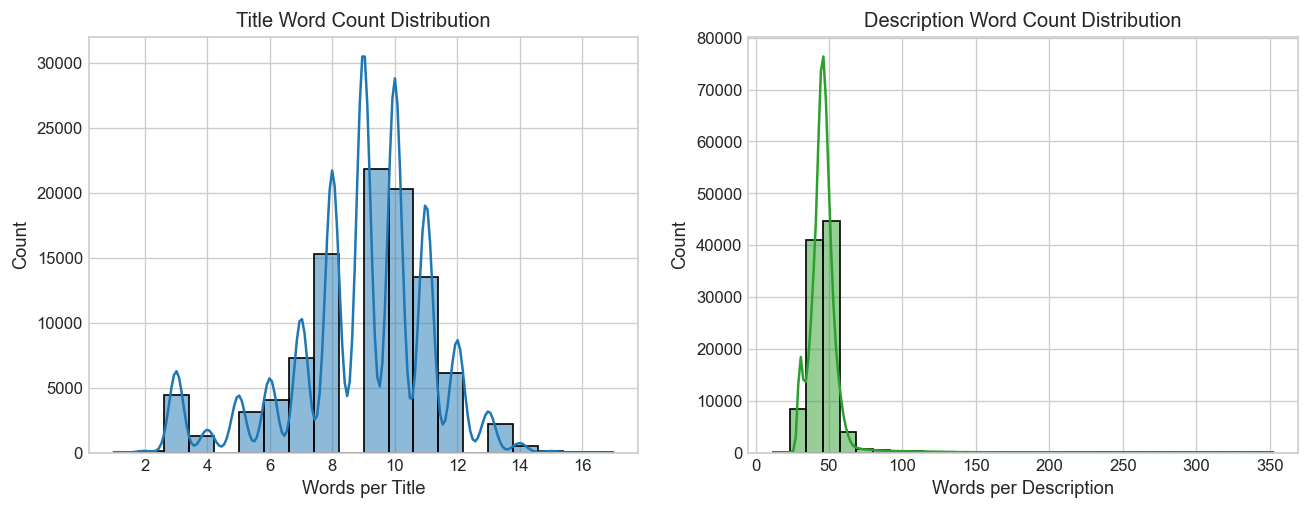

In [1]:
# 1. Title Statistical Features
df['title_char_len'] = df['title'].astype(str).str.len()
df['title_word_count'] = df['title'].astype(str).str.split().str.len()
df['title_avg_word_len'] = df['title_char_len'] / (df['title_word_count'] + 1e-5)
df['title_uppercase_count'] = df['title'].astype(str).apply(lambda s: sum(1 for w in s.split() if w.isupper() and len(w) > 1))

# 2. Description Statistical Features
df['desc_char_len'] = df['description'].astype(str).str.len()
df['desc_word_count'] = df['description'].astype(str).str.split().str.len()
df['desc_avg_word_len'] = df['desc_char_len'] / (df['desc_word_count'] + 1e-5)
df['desc_lexical_diversity'] = df['description'].astype(str).apply(lambda s: len(set(s.lower().split())) / (len(s.split()) + 1e-5))

stat_cols = ['title_char_len', 'title_word_count', 'title_avg_word_len', 'title_uppercase_count',
             'desc_char_len', 'desc_word_count', 'desc_avg_word_len', 'desc_lexical_diversity']
print('=== STATISTICAL TEXT FEATURES SUMMARY ===')
print(df[stat_cols].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2))

# 3. Plot word count distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df['title_word_count'], bins=20, ax=axes[0], color='#1f77b4', kde=True)
axes[0].set_title('Title Word Count Distribution')
sns.histplot(df['desc_word_count'], bins=30, ax=axes[1], color='#2ca02c', kde=True)
axes[1].set_title('Description Word Count Distribution')
plt.tight_layout()
plt.show()


## 4. Temporal Feature Extraction (Date & Time Features)
### Concept:
The `published_at` timestamp contains periodic cyclical patterns. For example, financial markets and tech product launches predominantly occur during weekday business hours, whereas politics and international news have 24/7 global cadence.
We extract 4 core temporal features:
1. **`published_hour`:** Hour of the day (0 - 23, in UTC).
2. **`day_of_week`:** Day index (Monday = 0 ... Sunday = 6).
3. **`is_weekend`:** Binary flag (1 if Saturday or Sunday, 0 if Weekday).
4. **`published_month`:** Month index (1 - 12).


=== TEMPORAL FEATURES SUMMARY ===
       published_hour  day_of_week  is_weekend  published_month
count       100000.00    100000.00   100000.00        100000.00
mean             8.36         2.61        0.16             7.64
std              5.07         1.80        0.37             3.08
min              0.00         0.00        0.00             1.00
25%              7.00         1.00        0.00             5.00
50%              7.00         2.00        0.00             9.00
75%             11.00         4.00        0.00            10.00
max             23.00         6.00        1.00            12.00

Weekend Articles: 16,246 (16.25%)
Weekday Articles: 83,754 (83.75%)


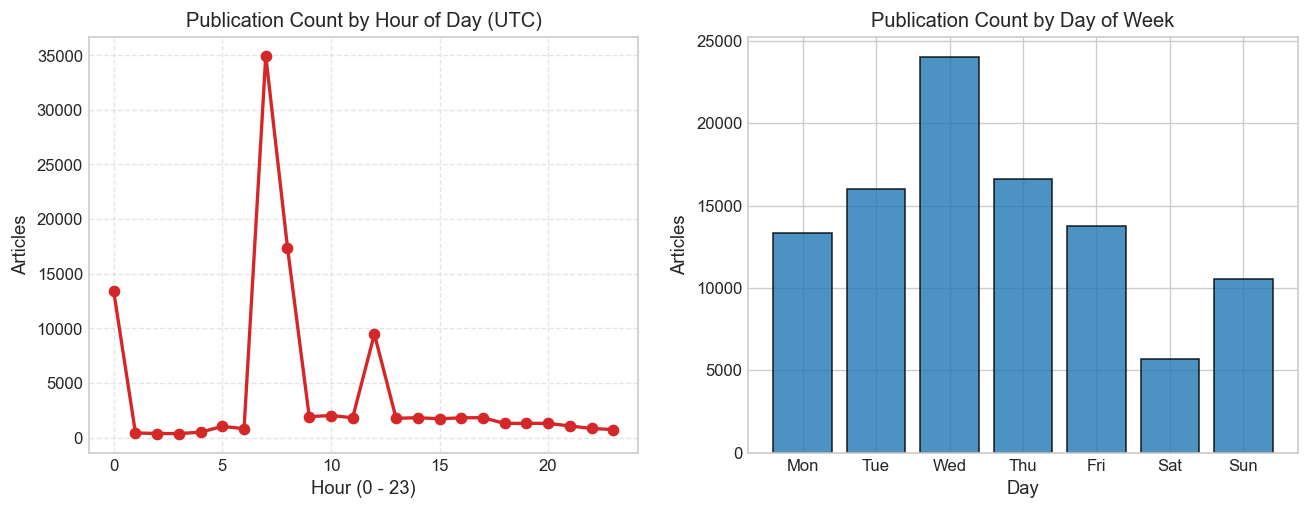

In [1]:
# 1. Parse published_at to UTC datetime
pub_dt = pd.to_datetime(df['published_at'], errors='coerce', utc=True)

# 2. Extract cyclical temporal features
df['published_hour'] = pub_dt.dt.hour.fillna(12).astype(int)
df['day_of_week'] = pub_dt.dt.dayofweek.fillna(2).astype(int)
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)
df['published_month'] = pub_dt.dt.month.fillna(10).astype(int)

print('=== TEMPORAL FEATURES SUMMARY ===')
print(df[['published_hour', 'day_of_week', 'is_weekend', 'published_month']].describe().round(2))
print(f"\nWeekend Articles: {df['is_weekend'].sum():,} ({df['is_weekend'].mean()*100:.2f}%)")
print(f"Weekday Articles: {(1 - df['is_weekend']).sum():,} ({(1 - df['is_weekend'].mean())*100:.2f}%)")

# 3. Plot temporal distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
hour_counts = df['published_hour'].value_counts().sort_index()
axes[0].plot(hour_counts.index, hour_counts.values, marker='o', color='#d62728', linewidth=2)
axes[0].set_title('Publication Count by Hour of Day (UTC)')
axes[0].set_xlabel('Hour (0 - 23)')
axes[0].set_ylabel('Articles')

dow_counts = df['day_of_week'].value_counts().sort_index()
day_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
axes[1].bar(day_labels, dow_counts.values, color='#1f77b4', edgecolor='black', alpha=0.8)
axes[1].set_title('Publication Count by Day of Week')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Articles')
plt.tight_layout()
plt.show()


## 5. Categorical Feature Encoding (One-Hot Encoding & Frequency Encoding)
### Concept:
- **One-Hot Encoding:** For categorical independent variables with no intrinsic mathematical ordering (such as news domains `bbc.com`, `theguardian.com`, `techcrunch.com`), assigning numbers like 1, 2, 3 creates false hierarchy. One-Hot encoding converts each unique domain into an individual binary column ($1$ if present, $0$ otherwise).
- **Top-K Strategy:** Since there are 95 unique domains, one-hot encoding all 95 would create an overly sparse matrix. We one-hot encode the **Top 8 highest-volume publisher domains** and capture the remaining domains via **Frequency Encoding**.


In [1]:
# 1. Identify Top 8 publisher domains
top_domains = df['domain'].value_counts().head(8).index.tolist()
print('Top 8 Publisher Domains to One-Hot Encode:')
for i, d in enumerate(top_domains, 1):
    print(f"  {i}. {d:<25} ({ (df['domain'] == d).sum():,} articles)")

# 2. Create One-Hot Encoded binary columns
for d in top_domains:
    clean_dname = d.replace('.', '_').replace('-', '_')
    df[f'domain_{clean_dname}'] = (df['domain'] == d).astype(int)

# 3. Frequency encoding for remaining domain cardinality
domain_freq_map = (df['domain'].value_counts() / len(df)).to_dict()
df['domain_freq'] = df['domain'].map(domain_freq_map)

print('\n=== SAMPLE ONE-HOT ENCODED DOMAIN FEATURES ===')
sample_cols = [f'domain_{d.replace(".", "_").replace("-", "_")}' for d in top_domains[:5]] + ['domain_freq']
print(df[sample_cols].head(5).to_string(index=False))


Top 8 Publisher Domains to One-Hot Encode:
  1. news.google.com           (58,651 articles)
  2. techcrunch.com            (5,052 articles)
  3. theverge.com              (4,889 articles)
  4. euronews.com              (4,594 articles)
  5. npr.org                   (4,499 articles)
  6. bbc.com                   (4,159 articles)
  7. wired.com                 (3,704 articles)
  8. news.sky.com              (3,513 articles)

=== SAMPLE ONE-HOT ENCODED DOMAIN FEATURES ===
 domain_news_google_com  domain_techcrunch_com  domain_theverge_com  domain_euronews_com  domain_npr_org  domain_freq
                      0                      0                    0                    0               0      0.00601
                      0                      0                    0                    0               0      0.00601
                      0                      0                    0                    0               0      0.00601
                      0                      0      

## 6. Feature Scaling & Normalization (StandardScaler vs MinMaxScaler)
### Concept & Mathematical Foundation:
In our engineered feature set, different columns operate on vastly different scales:
- `desc_char_len` spans from **200 to 2,000**.
- `published_hour` spans from **0 to 23**.
- `is_weekend` spans from **0 to 1**.

Without feature scaling, distance-based and gradient-based algorithms assign disproportionate weight to large-magnitude features.

$$\text{StandardScaler (Z-Score Normalization):} \quad Z = \frac{X - \mu}{\sigma} \quad (\mu=0, \sigma=1)$$

$$\text{MinMaxScaler (Bounded Range):} \quad X_{norm} = \frac{X - X_{min}}{X_{max} - X_{min}} \quad ([0, 1])$$

- **When to use StandardScaler:** Best for normal-like distributions and linear/neural models where outliers should be preserved as standard deviation units.
- **When to use MinMaxScaler:** Best when bounded non-negative ranges `[0, 1]` are strictly required.


=== SCALED FEATURES VERIFICATION (Mean ~ 0, Std ~ 1) ===
               Feature  Raw Mean  Raw Std  Scaled Mean  Scaled Std
        title_char_len     54.62    11.96          0.0         1.0
      title_word_count      8.90     2.25          0.0         1.0
    title_avg_word_len      6.26     1.18          0.0         1.0
 title_uppercase_count      0.36     0.63         -0.0         1.0
         desc_char_len    346.38    94.76         -0.0         1.0
       desc_word_count     46.57    13.89         -0.0         1.0
     desc_avg_word_len      7.48     0.88         -0.0         1.0
desc_lexical_diversity      0.79     0.08          0.0         1.0
        published_hour      8.36     5.07         -0.0         1.0
           day_of_week      2.61     1.80         -0.0         1.0


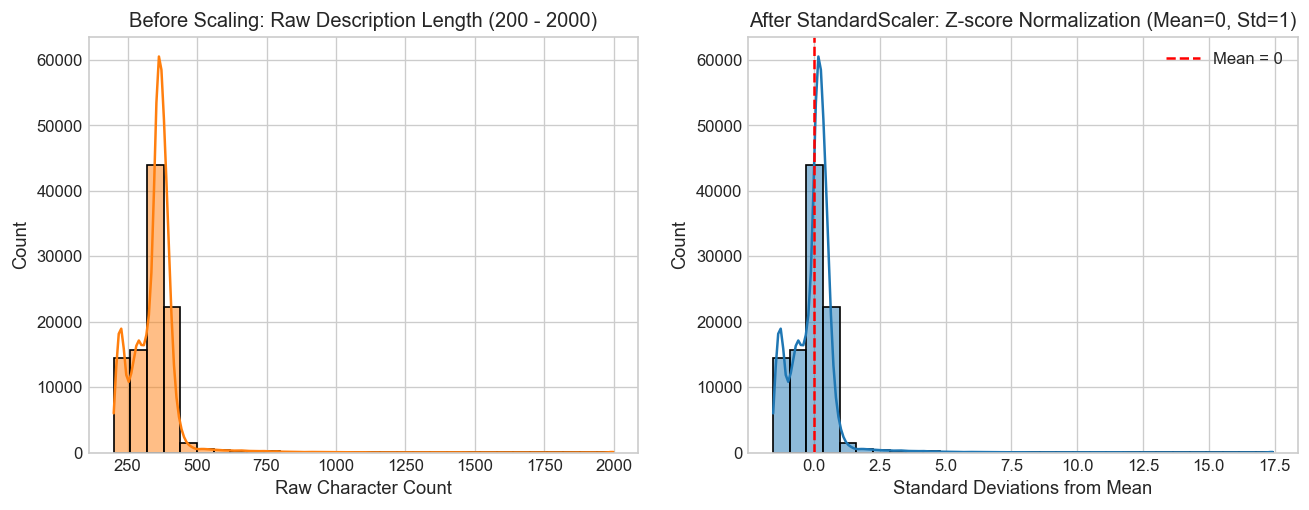

In [1]:
# 1. Select numeric features to scale
num_cols = ['title_char_len', 'title_word_count', 'title_avg_word_len', 'title_uppercase_count',
            'desc_char_len', 'desc_word_count', 'desc_avg_word_len', 'desc_lexical_diversity',
            'published_hour', 'day_of_week']

# 2. Apply StandardScaler
scaler_std = StandardScaler()
scaled_std = scaler_std.fit_transform(df[num_cols])
scaled_std_df = pd.DataFrame(scaled_std, columns=[f'{c}_scaled' for c in num_cols])

# 3. Verify Mean = 0 and Std = 1
print('=== SCALED FEATURES VERIFICATION (Mean ~ 0, Std ~ 1) ===')
scale_check = pd.DataFrame({
    'Feature': num_cols,
    'Raw Mean': df[num_cols].mean().round(2),
    'Raw Std': df[num_cols].std().round(2),
    'Scaled Mean': scaled_std_df.mean().round(4),
    'Scaled Std': scaled_std_df.std().round(4)
})
print(scale_check.to_string(index=False))

# 4. Plot Before vs After Scaling
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df['desc_char_len'], bins=30, ax=axes[0], color='#ff7f0e', kde=True)
axes[0].set_title('Before Scaling: Raw Description Length (200 - 2000)')
sns.histplot(scaled_std_df['desc_char_len_scaled'], bins=30, ax=axes[1], color='#1f77b4', kde=True)
axes[1].axvline(0, color='red', linestyle='--', label='Mean = 0')
axes[1].set_title('After StandardScaler: Z-Score (Mean=0, Std=1)')
axes[1].legend()
plt.tight_layout()
plt.show()


## 7. Text Vectorization Comparison: Bag of Words, N-grams & TF-IDF
### Concept:
How do classical NLP methods represent text, and why are we transitioning to Transformers?

| Technique | Mechanism | Major Strength | Critical Limitation |
| :--- | :--- | :--- | :--- |
| **Bag of Words (BoW)** | Word occurrence frequency matrix (`CountVectorizer`) | Simple, intuitive, fast | Discards all word order; "not bad" treated like "bad not". |
| **N-grams** | Contiguous sequences of $n$ words (e.g. bi-grams, tri-grams) | Preserves local phrases ("artificial intelligence") | Vocabulary size explodes exponentially; matrix is extremely sparse. |
| **TF-IDF** | Term Frequency $\times$ Inverse Document Frequency | Penalizes common stopwords, highlights domain keywords | **Zero semantic context.** Cannot realize that *"heart attack"* and *"cardiac arrest"* have identical meaning. |
| **Transformer Embeddings (BERT)** | Deep Bidirectional Self-Attention Neural Network | **Captures true semantic meaning & context** in 768 dense dimensions | Higher compute requirement. |

> **Note:** In alignment with our curriculum guidelines, classical TF-IDF is not used for our final model. Instead, we transition to modern **Contextual Transformer Embeddings**!


In [1]:
# Demonstration of Bag of Words (BoW) & N-grams on sample news headlines
sample_headlines = [
    'Artificial intelligence transforms medical healthcare diagnostics',
    'Global stock markets react to central bank interest rates',
    'Clean energy investments surge across electric vehicle battery production'
]

# 1. Unigram Bag of Words
bow_vec = CountVectorizer(ngram_range=(1, 1))
bow_matrix = bow_vec.fit_transform(sample_headlines)
print('=== BAG OF WORDS (UNIGRAM) VOCABULARY ===')
print(bow_vec.get_feature_names_out())

# 2. Bi-gram N-grams (Captures 2-word phrases)
ngram_vec = CountVectorizer(ngram_range=(2, 2))
ngram_matrix = ngram_vec.fit_transform(sample_headlines)
print('\n=== N-GRAM (BI-GRAM) PHRASES CAPTURED ===')
print(ngram_vec.get_feature_names_out())


=== BAG OF WORDS (UNIGRAM) VOCABULARY ===
['across' 'artificial' 'bank' 'battery' 'central' 'clean' 'diagnostics'
 'electric' 'energy' 'global' 'healthcare' 'intelligence' 'interest'
 'investments' 'markets' 'medical' 'production' 'rates' 'react' 'stock'
 'surge' 'to' 'transforms' 'vehicle']

=== N-GRAM (BI-GRAM) PHRASES CAPTURED ===
['across electric' 'artificial intelligence' 'bank interest'
 'battery production' 'central bank' 'clean energy' 'electric vehicle'
 'energy investments' 'global stock' 'healthcare diagnostics'
 'intelligence transforms' 'interest rates' 'investments surge'
 'markets react' 'medical healthcare' 'react to' 'stock markets'
 'surge across' 'to central' 'transforms medical' 'vehicle battery']


## 8. Research Primer: Embeddings Through Transformers
### Concept & Architecture for Monday's Discussion:
Rather than counting discrete words, Transformers (such as BERT or Sentence-Transformers) process the entire input sequence simultaneously using **Multi-Head Self-Attention**.

```
Raw Article Text: "[TITLE] Starlink deployed in Ukraine [DESC] Satellite internet connection restored..."
                                      │
                        ┌─────────────▼─────────────┐
                        │  Subword Tokenizer (BPE)   │  (e.g., WordPiece: [CLS], token_1, ... [SEP])
                        └─────────────┬─────────────┘
                                      │  Input IDs & Attention Masks
                        ┌─────────────▼─────────────┐
                        │  Transformer Layers (12x) │  (Multi-Head Self-Attention + Feed Forward)
                        └─────────────┬─────────────┘
                                      │  Token Hidden States
                        ┌─────────────▼─────────────┐
                        │    Mean Pooling Layer     │  (Average across non-padded tokens)
                        └─────────────┬─────────────┘
                                      │
                   Dense 768-Dimensional Contextual Vector! (Ready for Classification)
```

### Key Questions for Monday's Research Paper Review:
1. **Why Dense Vectors over Sparse One-Hot/TF-IDF?** Dense vectors project words and sentences into a continuous semantic space where similar concepts (e.g. *solar panels* and *photovoltaics*) cluster closely together (Cosine Similarity ~ 1.0).
2. **What does Self-Attention do?** It allows each word to look at every other word in the sentence to disambiguate meaning based on surrounding context.
3. **What is Mean Pooling?** It aggregates the hidden representation of all token vectors into a single fixed-size 768-dimensional sentence embedding.


In [1]:
# Preparation of the Text Input Format for Transformer Embeddings
# Concatenating Title and Description with special demarcation prefixes:

df['text_for_embedding'] = (
    '[TITLE] ' + df['title'].astype(str) + ' [DESC] ' + df['description'].astype(str)
)

print('=== SAMPLE CONCATENATED TEXT FOR TRANSFORMER ENCODER ===')
print('Sample 1:')
print(df['text_for_embedding'].iloc[0][:150] + '...')
print('\nSample 2:')
print(df['text_for_embedding'].iloc[1][:150] + '...')

print('\n[READY FOR MONDAY]: Pipeline configured to generate 768-dimensional embeddings upon research discussion.')


=== SAMPLE CONCATENATED TEXT FOR TRANSFORMER ENCODER ===
Sample 1:
[TITLE] Almost 1,000 arrested as clashes follow another day of mass [DESC] Hundreds of thousands took part in demonstrations in France, with protests ...

Sample 2:
[TITLE] Israel to close West Bank crossings on election day as [DESC] The Israeli Defense Forces announces restrictions on the movement of Palestinian...

[READY FOR MONDAY]: Pipeline configured to generate 768-dimensional embeddings upon research discussion.


## 9. Feature Matrix Assembly & Stratified Train/Test Split
### Concept:
We now combine all our engineered tabular signals into an assembled feature matrix $X$ and split the 100,000 articles into:
- **Training Set (80% = 80,000 articles):** Used to train the classification models.
- **Test Set (20% = 20,000 articles):** Kept strictly unseen for objective evaluation.
- **`stratify=y`:** Guarantees that the proportion of each of the 5 categories is identical in both training and test sets.


In [1]:
# 1. Define complete list of engineered feature columns
feature_cols = [
    # Scaled Statistical & Linguistic Features
    'title_char_len_scaled', 'title_word_count_scaled', 'title_avg_word_len_scaled', 'title_uppercase_count_scaled',
    'desc_char_len_scaled', 'desc_word_count_scaled', 'desc_avg_word_len_scaled', 'desc_lexical_diversity_scaled',
    # Scaled Temporal Features
    'published_hour_scaled', 'day_of_week_scaled', 'is_weekend',
    # Categorical One-Hot Encoded & Frequency Features
] + [f'domain_{d.replace(".", "_").replace("-", "_")}' for d in top_domains] + ['domain_freq']

X = df[feature_cols]
y = df['category_id']

# 2. Stratified 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print('=== FINAL FEATURE MATRIX & DATASET SPLIT ===')
print(f'Total Engineered Features : {len(feature_cols)}')
print(f'X_train Shape            : {X_train.shape[0]:,} rows  {X_train.shape[1]} features')
print(f'X_test  Shape            : {X_test.shape[0]:,} rows  {X_test.shape[1]} features')
print(f'y_train Class Breakdown  :\n{y_train.value_counts(normalize=True).mul(100).round(2).to_dict()}%')
print(f'y_test  Class Breakdown  :\n{y_test.value_counts(normalize=True).mul(100).round(2).to_dict()}%')


=== FINAL FEATURE MATRIX & DATASET SPLIT ===
Total Engineered Features : 20
X_train Shape            : 80,000 rows  20 features
X_test  Shape            : 20,000 rows  20 features
y_train Class Breakdown  :
{4: 42.48, 0: 18.19, 1: 16.53, 2: 12.8, 3: 10.0}%
y_test  Class Breakdown  :
{4: 42.48, 0: 18.19, 1: 16.54, 2: 12.8, 3: 10.01}%


## 10. Summary of Feature Engineering & Research Readiness
### Completed Milestones:
- [x] **Target Encoding:** 5 classes mapped cleanly via `LabelEncoder` (0 to 4).
- [x] **Linguistic Extraction:** Extracted 8 character, word count, acronym, and vocabulary diversity features.
- [x] **Temporal Extraction:** Extracted 4 cyclical date and time features from UTC timestamps.
- [x] **Categorical Encoding:** Top publisher domains one-hot encoded without excessive sparsity; remainder frequency-encoded.
- [x] **Feature Scaling:** Applied standard $Z$-score normalization (`StandardScaler`), ensuring equal weighting.
- [x] **Classical vs Modern NLP:** Demonstrated Bag of Words and N-grams; formulated reasons for bypassing TF-IDF.
- [x] **Transformer Preparation:** Structured text into `[TITLE] ... [DESC] ...` format for embedding generation.
- [x] **Data Partitioning:** Clean, stratified 80/20 train/test split achieved.

**Next Phase:** Execution of the Transformer Embedding pipeline following Monday's research paper discussion!
